In [1]:

# STEP 1: IMPORT REQUIRED LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import joblib

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:

!pip install -q ucimlrepo


In [5]:

# STEP 2: DATA COLLECTION AND LOADING

from ucimlrepo import fetch_ucirepo

# Fetch dataset from UCI Repository
dataset = fetch_ucirepo(id=468)

# Separate features and target
X = dataset.data.features
y = dataset.data.targets

# Combine into one dataframe
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())



Dataset loaded successfully!
Dataset shape: (12330, 18)

First five records:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [6]:

# STEP 3: DATA UNDERSTANDING

# Display dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  T

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462,10422
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


In [7]:

# STEP 4: DATA CLEANING

# Remove duplicate records
df = df.drop_duplicates()

# Separate input features and target variable
X = df.drop("Revenue", axis=1)
y = df["Revenue"].astype(int)

print("Data cleaning completed!")

print("\nDataset shape after removing duplicates:")
print(df.shape)

print("\nInput features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nPurchase Distribution:")
print(y.value_counts())

print("\nPurchase Percentage:")
print(y.value_counts(normalize=True) * 100)


Data cleaning completed!

Dataset shape after removing duplicates:
(12205, 18)

Input features shape: (12205, 17)
Target variable shape: (12205,)

Purchase Distribution:
Revenue
0    10297
1     1908
Name: count, dtype: int64

Purchase Percentage:
Revenue
0    84.367063
1    15.632937
Name: proportion, dtype: float64


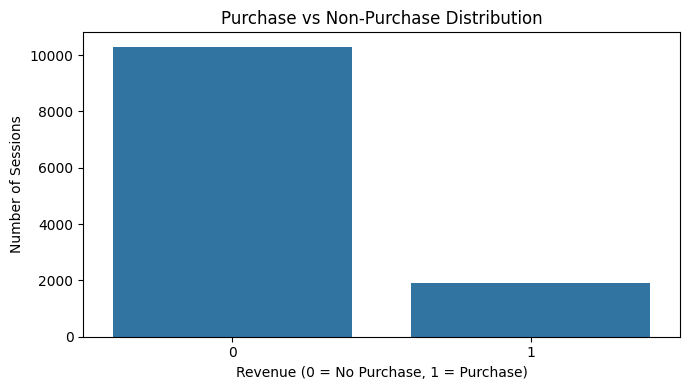

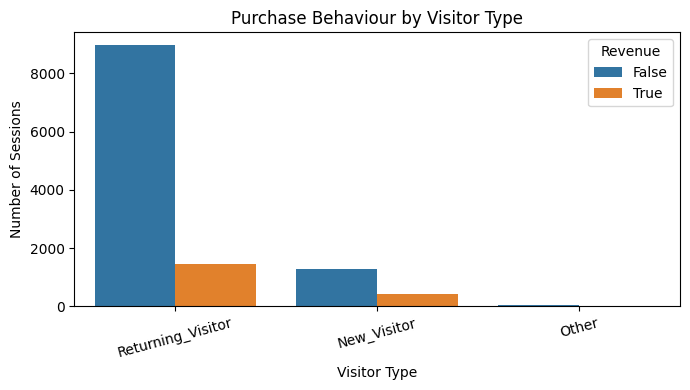

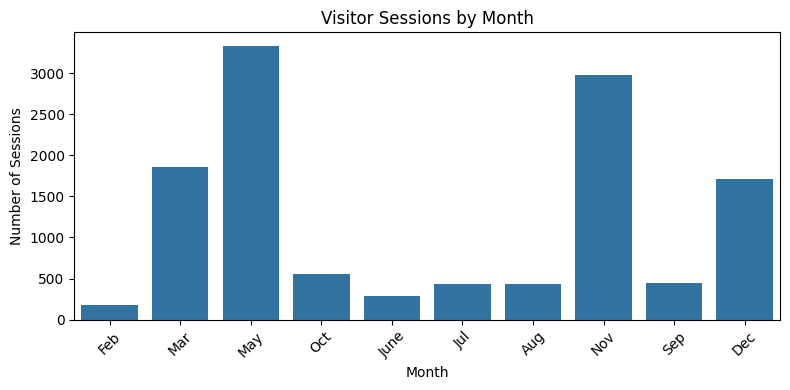

Exploratory Data Analysis completed!


In [10]:
# STEP 5: EXPLORATORY DATA ANALYSIS
# Graph 1: Purchase vs Non-Purchase Distribution
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(x=y, ax=ax)
ax.set_title("Purchase vs Non-Purchase Distribution")
ax.set_xlabel("Revenue (0 = No Purchase, 1 = Purchase)")
ax.set_ylabel("Number of Sessions")
plt.tight_layout()
plt.show()
plt.close(fig)


# Graph 2: Purchase Behaviour by Visitor Type
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="VisitorType", hue="Revenue", ax=ax)
ax.set_title("Purchase Behaviour by Visitor Type")
ax.set_xlabel("Visitor Type")
ax.set_ylabel("Number of Sessions")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
plt.close(fig)


# Graph 3: Monthly Visitor Distribution
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=df, x="Month", ax=ax)
ax.set_title("Visitor Sessions by Month")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.close(fig)

print("Exploratory Data Analysis completed!")

In [11]:
# STEP 6: DATA PREPROCESSING AND TRAIN-TEST SPLIT

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object", "bool", "category"]
).columns

# Preprocess numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data preprocessing completed!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Data preprocessing completed!
Training data shape: (9764, 17)
Testing data shape: (2441, 17)


In [12]:
# STEP 7: LOGISTIC REGRESSION MODEL TRAINING

# Create the Logistic Regression model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
# STEP 8: MODEL PREDICTION

# Predict purchase behaviour
y_pred = model.predict(X_test)

# Predict purchase probabilities
y_prob = model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions completed successfully!

First 10 Actual Values:
[0 0 0 0 0 0 0 0 0 0]

First 10 Predicted Values:
[0 0 0 0 0 1 0 0 0 0]


In [14]:
# STEP 9: MODEL EVALUATION

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")
print("ROC-AUC Score:", round(roc_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

MODEL EVALUATION RESULTS
------------------------
Accuracy: 85.13 %
Precision: 51.64 %
Recall: 78.53 %
F1 Score: 62.31 %
ROC-AUC Score: 0.9109

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.86      0.91      2059
           1       0.52      0.79      0.62       382

    accuracy                           0.85      2441
   macro avg       0.74      0.82      0.77      2441
weighted avg       0.89      0.85      0.86      2441



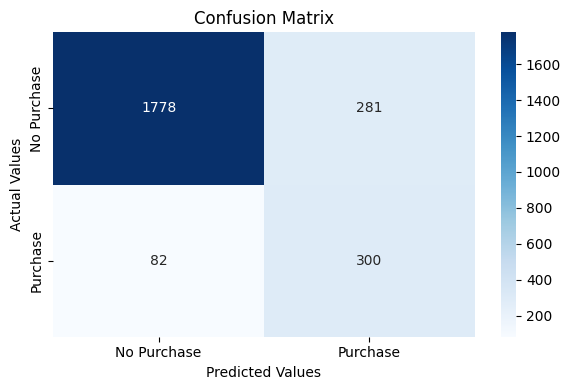

Confusion Matrix generated successfully!


In [15]:
# STEP 10: CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.tight_layout()
plt.show()

print("Confusion Matrix generated successfully!")

In [16]:
# STEP 11: INSTALL AND IMPORT GRADIO

!pip install -q gradio

import gradio as gr

print("Gradio is ready!")
print("Version:", gr.__version__)

Gradio is ready!
Version: 6.31.0


In [17]:
# STEP 12: SAVE TRAINED MODEL

joblib.dump(model, "online_purchase_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [18]:
import os

print("Model file exists:", os.path.exists("online_purchase_model.pkl"))

Model file exists: True


In [19]:
# STEP 13: CREATE UNKNOWN CUSTOMER DATASET

unknown_data = pd.DataFrame([
    {
        "Administrative": 2,
        "Administrative_Duration": 45.0,
        "Informational": 1,
        "Informational_Duration": 30.0,
        "ProductRelated": 15,
        "ProductRelated_Duration": 600.0,
        "BounceRates": 0.02,
        "ExitRates": 0.04,
        "PageValues": 12.5,
        "SpecialDay": 0.0,
        "Month": "Nov",
        "OperatingSystems": 2,
        "Browser": 2,
        "Region": 1,
        "TrafficType": 2,
        "VisitorType": "Returning_Visitor",
        "Weekend": True
    },
    {
        "Administrative": 0,
        "Administrative_Duration": 0.0,
        "Informational": 0,
        "Informational_Duration": 0.0,
        "ProductRelated": 3,
        "ProductRelated_Duration": 60.0,
        "BounceRates": 0.15,
        "ExitRates": 0.20,
        "PageValues": 0.0,
        "SpecialDay": 0.0,
        "Month": "Feb",
        "OperatingSystems": 1,
        "Browser": 1,
        "Region": 2,
        "TrafficType": 3,
        "VisitorType": "New_Visitor",
        "Weekend": False
    },
    {
        "Administrative": 4,
        "Administrative_Duration": 100.0,
        "Informational": 2,
        "Informational_Duration": 50.0,
        "ProductRelated": 25,
        "ProductRelated_Duration": 1200.0,
        "BounceRates": 0.01,
        "ExitRates": 0.03,
        "PageValues": 25.0,
        "SpecialDay": 0.0,
        "Month": "May",
        "OperatingSystems": 3,
        "Browser": 2,
        "Region": 3,
        "TrafficType": 2,
        "VisitorType": "Returning_Visitor",
        "Weekend": False
    },
    {
        "Administrative": 1,
        "Administrative_Duration": 10.0,
        "Informational": 0,
        "Informational_Duration": 0.0,
        "ProductRelated": 5,
        "ProductRelated_Duration": 120.0,
        "BounceRates": 0.10,
        "ExitRates": 0.15,
        "PageValues": 0.0,
        "SpecialDay": 0.0,
        "Month": "Jul",
        "OperatingSystems": 2,
        "Browser": 4,
        "Region": 1,
        "TrafficType": 4,
        "VisitorType": "New_Visitor",
        "Weekend": True
    },
    {
        "Administrative": 3,
        "Administrative_Duration": 80.0,
        "Informational": 1,
        "Informational_Duration": 25.0,
        "ProductRelated": 40,
        "ProductRelated_Duration": 1800.0,
        "BounceRates": 0.01,
        "ExitRates": 0.02,
        "PageValues": 40.0,
        "SpecialDay": 0.0,
        "Month": "Nov",
        "OperatingSystems": 2,
        "Browser": 2,
        "Region": 4,
        "TrafficType": 1,
        "VisitorType": "Returning_Visitor",
        "Weekend": False
    }
])

print("Unknown customer dataset created!")
print("Dataset shape:", unknown_data.shape)

display(unknown_data)

Unknown customer dataset created!
Dataset shape: (5, 17)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,2,45.0,1,30.0,15,600.0,0.02,0.04,12.5,0.0,Nov,2,2,1,2,Returning_Visitor,True
1,0,0.0,0,0.0,3,60.0,0.15,0.20,0.0,0.0,Feb,1,1,2,3,New_Visitor,False
2,4,100.0,2,50.0,25,1200.0,0.01,0.03,25.0,0.0,May,3,2,3,2,Returning_Visitor,False
3,1,10.0,0,0.0,5,120.0,0.10,0.15,0.0,0.0,Jul,2,4,1,4,New_Visitor,True
4,3,80.0,1,25.0,40,1800.0,0.01,0.02,40.0,0.0,Nov,2,2,4,1,Returning_Visitor,False


In [20]:
# STEP 14: UNKNOWN CUSTOMER PREDICTION

# Predict purchase behaviour
unknown_predictions = model.predict(unknown_data)

# Calculate purchase probabilities
unknown_probabilities = model.predict_proba(unknown_data)[:, 1]

# Create prediction results
prediction_results = unknown_data.copy()

prediction_results["Predicted_Revenue"] = unknown_predictions

prediction_results["Purchase_Probability_%"] = (
    unknown_probabilities * 100
).round(2)

prediction_results["Prediction"] = pd.Series(
    unknown_predictions
).map({
    0: "No Purchase",
    1: "Purchase"
}).values

print("Unknown customer predictions completed!")

display(prediction_results[
    ["Predicted_Revenue", "Purchase_Probability_%", "Prediction"]
])

Unknown customer predictions completed!


,Predicted_Revenue,Purchase_Probability_%,Prediction
0,1,75.80,Purchase
1,0,0.64,No Purchase
2,1,78.75,Purchase
3,0,8.38,No Purchase
4,1,99.17,Purchase


In [21]:
# STEP 15: EXPORT PREDICTION RESULTS

prediction_results.to_csv(
    "online_purchase_predictions.csv",
    index=False
)

print("Prediction results exported successfully!")
print("File: online_purchase_predictions.csv")

Prediction results exported successfully!
File: online_purchase_predictions.csv


In [22]:
from google.colab import files

files.download("online_purchase_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# STEP 16: DASHBOARD PERFORMANCE METRICS

from sklearn.metrics import balanced_accuracy_score

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Balanced Accuracy"
    ],
    "Score (%)": [
        round(accuracy_score(y_test, y_pred) * 100, 2),
        round(precision_score(y_test, y_pred) * 100, 2),
        round(recall_score(y_test, y_pred) * 100, 2),
        round(f1_score(y_test, y_pred) * 100, 2),
        round(roc_auc_score(y_test, y_prob) * 100, 2),
        round(balanced_accuracy_score(y_test, y_pred) * 100, 2)
    ]
})

display(metrics_df)

,Metric,Score (%)
0,Accuracy,85.13
1,Precision,51.64
2,Recall,78.53
3,F1 Score,62.31
4,ROC-AUC,91.09
5,Balanced Accuracy,82.44


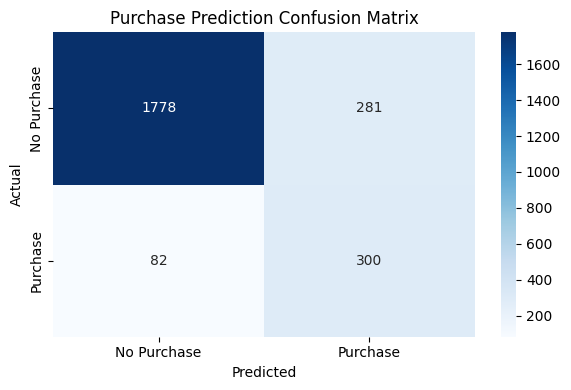

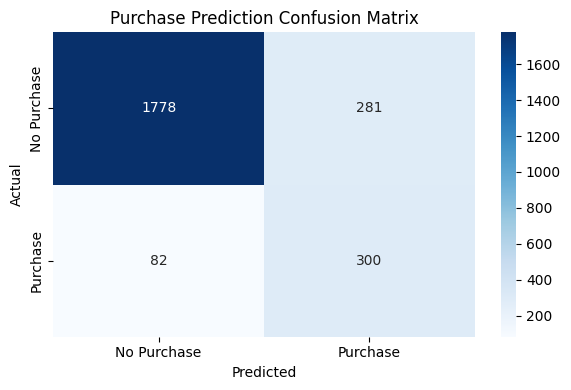

In [24]:
# STEP 17: CONFUSION MATRIX VISUALIZATION(after including gradio function)

def create_confusion_matrix():

    cm = confusion_matrix(y_test, y_pred)

    fig, ax = plt.subplots(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Purchase", "Purchase"],
        yticklabels=["No Purchase", "Purchase"],
        ax=ax
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("Purchase Prediction Confusion Matrix")

    plt.tight_layout()

    return fig


display(create_confusion_matrix())
#2 graphs is because one is from this step and the other is from step 10
#before and after gradio func

In [25]:
# STEP 18: CSV UPLOAD PREDICTION FUNCTION

def predict_csv(file_path):

    if file_path is None:
        raise gr.Error("Please upload a CSV file.")

    # Read uploaded CSV
    data = pd.read_csv(file_path)

    if data.empty:
        raise gr.Error("The uploaded CSV is empty.")

    # Remove target column if present
    data = data.drop(columns=["Revenue"], errors="ignore")

    # Check required columns
    missing_columns = [
        col for col in X.columns if col not in data.columns
    ]

    if missing_columns:
        raise gr.Error(
            f"Missing required columns: {missing_columns}"
        )

    # Keep features in correct order
    data = data[X.columns]

    # Make predictions
    predictions = model.predict(data)
    probabilities = model.predict_proba(data)[:, 1]

    # Create results
    results = data.copy()

    results["Predicted_Revenue"] = predictions
    results["Prediction"] = [
        "Purchase" if p == 1 else "No Purchase"
        for p in predictions
    ]

    results["Purchase_Probability_%"] = (
        probabilities * 100
    ).round(2)

    # Save results
    results.to_csv(
        "/content/online_purchase_csv_results.csv",
        index=False
    )

    # Summary
    summary = (
        f"Total Customers: {len(results)}\n"
        f"Predicted Purchases: {(predictions == 1).sum()}\n"
        f"Predicted No Purchases: {(predictions == 0).sum()}"
    )

    return summary, results, "/content/online_purchase_csv_results.csv"


print("CSV prediction function created successfully!")

CSV prediction function created successfully!


In [26]:
# STEP 19: MANUAL CUSTOMER PREDICTION

def predict_manual(*values):

    # Create a customer record
    customer_data = pd.DataFrame(
        [values],
        columns=X.columns
    )

    # Predict purchase behaviour
    prediction = model.predict(customer_data)[0]

    # Calculate probabilities
    probabilities = model.predict_proba(customer_data)[0]

    no_purchase_probability = round(probabilities[0] * 100, 2)
    purchase_probability = round(probabilities[1] * 100, 2)

    result = (
        "PURCHASE" if prediction == 1
        else "NO PURCHASE"
    )

    details = pd.DataFrame({
        "Prediction": [result],
        "No Purchase Probability (%)": [no_purchase_probability],
        "Purchase Probability (%)": [purchase_probability]
    })

    return result, details


print("Manual customer prediction function created successfully!")

Manual customer prediction function created successfully!


In [29]:
# CREATE SAMPLE CSV FOR DASHBOARD TESTING

unknown_data.to_csv(
    "sample_customer_data.csv",
    index=False
)

from google.colab import files

files.download("sample_customer_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
# STEP 20: BUILD THE INTERACTIVE DASHBOARD

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Online Purchase Prediction System"
) as demo:

    # PROJECT HEADER
    gr.Markdown("""
    # 🛒 Online Purchase Prediction System

    ### Machine Learning Project using Logistic Regression

    Predict whether an online visitor is likely to make a purchase
    based on their website browsing behaviour.
    """)

    gr.Markdown("---")

    # SECTION 1: MODEL PERFORMANCE
    gr.Markdown("## 📊 Model Performance")

    gr.Dataframe(
        value=metrics_df,
        label="Model Evaluation Metrics",
        interactive=False
    )

    gr.Plot(
        value=create_confusion_matrix(),
        label="Confusion Matrix"
    )

    gr.Markdown("---")

    # SECTION 2: CSV UPLOAD
    gr.Markdown("""
    ## 📁 Predict Using CSV File

    Upload a CSV containing new customer browsing records.
    The system will generate purchase predictions and probabilities.
    """)

    csv_file = gr.File(
        label="Upload Customer CSV",
        file_types=[".csv"],
        type="filepath"
    )

    csv_button = gr.Button(
        "Predict Customer Purchases",
        variant="primary"
    )

    csv_summary = gr.Textbox(
        label="Prediction Summary",
        lines=3
    )

    csv_results = gr.Dataframe(
        label="Customer Prediction Results",
        interactive=False
    )

    csv_download = gr.File(
        label="Download Prediction Results"
    )

    csv_button.click(
        fn=predict_csv,
        inputs=csv_file,
        outputs=[
            csv_summary,
            csv_results,
            csv_download
        ]
    )

    gr.Markdown("---")

    # SECTION 3: MANUAL CUSTOMER INPUT
    gr.Markdown("""
    ## 👤 Manual Customer Prediction

    Enter a visitor's browsing details to predict their purchase behaviour.
    """)

    with gr.Row():
        with gr.Column():
            administrative = gr.Number(
                label="Administrative Pages", value=0
            )
            administrative_duration = gr.Number(
                label="Administrative Duration", value=0
            )
            informational = gr.Number(
                label="Informational Pages", value=0
            )
            informational_duration = gr.Number(
                label="Informational Duration", value=0
            )
            product_related = gr.Number(
                label="Product Related Pages", value=1
            )
            product_duration = gr.Number(
                label="Product Related Duration", value=30
            )

        with gr.Column():
            bounce_rates = gr.Number(
                label="Bounce Rates", value=0.02
            )
            exit_rates = gr.Number(
                label="Exit Rates", value=0.05
            )
            page_values = gr.Number(
                label="Page Values", value=0
            )
            special_day = gr.Number(
                label="Special Day", value=0
            )
            month = gr.Dropdown(
                label="Month",
                choices=[
                    "Jan", "Feb", "Mar", "Apr", "May", "June",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
                ],
                value="Nov"
            )
            operating_systems = gr.Number(
                label="Operating Systems", value=2
            )

        with gr.Column():
            browser = gr.Number(
                label="Browser", value=2
            )
            region = gr.Number(
                label="Region", value=1
            )
            traffic_type = gr.Number(
                label="Traffic Type", value=2
            )
            visitor_type = gr.Dropdown(
                label="Visitor Type",
                choices=[
                    "Returning_Visitor",
                    "New_Visitor",
                    "Other"
                ],
                value="Returning_Visitor"
            )
            weekend = gr.Checkbox(
                label="Weekend Visit",
                value=False
            )

    manual_button = gr.Button(
        "Predict Purchase Behaviour",
        variant="primary"
    )

    manual_result = gr.Textbox(
        label="Predicted Purchase Behaviour"
    )

    manual_details = gr.Dataframe(
        label="Purchase Probability Details",
        interactive=False
    )

    manual_button.click(
        fn=predict_manual,
        inputs=[
            administrative,
            administrative_duration,
            informational,
            informational_duration,
            product_related,
            product_duration,
            bounce_rates,
            exit_rates,
            page_values,
            special_day,
            month,
            operating_systems,
            browser,
            region,
            traffic_type,
            visitor_type,
            weekend
        ],
        outputs=[
            manual_result,
            manual_details
        ]
    )

    gr.Markdown("""
    ---
    **Project:** Online Purchase Prediction Using Logistic Regression

    **Dataset:** UCI Online Shoppers Purchasing Intention Dataset
    """)

print("Dashboard interface created successfully!")

/tmp/ipykernel_390/1104910260.py:3: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Dashboard interface created successfully!


In [28]:
demo.launch(share=True, theme=gr.themes.Soft())

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://743d6828eadd7100ee.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
